### Hisogram of slopes for ddG values on RANDOM split

In [1]:
""""
Copyright (C) 2025 ETH Zurich, Stefan J.P. Chrin, Gregory Landrum, Sereina Riniker
"""

import json
import os
import numpy as np
from scipy.stats import linregress
import matplotlib.pyplot as plt
import math



TARGET_COUNT_FILE = "../../../0_DATA/N_COMPOUNDS_PER_TARGET.json"

def load_target_counts(path):
    """
    Load target counts from JSON file.
    Args:
        path (str): path to JSON file
    Returns:
        dict: target -> count
    """
    with open(path, 'r') as f:
        return json.load(f)

def compute_slope_per_split(files, TARGETS_TO_SKIP):
    """
    Compute slope between predicted and experimental values per split.

    Args:
        files (dict): Dictionary mapping method names to file paths.
        TARGETS_TO_SKIP (set): Set of target names to skip.

    Returns:
        dict: Nested dictionary with slopes per method, target, and split.
    """
    slopes_all = {}

    for method, file_path in files.items():
        with open(file_path, 'r') as f:
            data = json.load(f)
        method_slopes = {}

        for split_idx, split in enumerate(data):
            for target in split:
                if target in TARGETS_TO_SKIP:
                    continue
                pairs = split[target]
                pred_list, exp_list = [], []

                for pair in sorted(pairs):
                    values = pairs[pair]
                    pred_list.append(values["prediction"])
                    exp_list.append(values["experimental"])

                # Skip if predictions or labels are constant
                if np.all(np.array(pred_list) == pred_list[0]) or np.all(np.array(exp_list) == exp_list[0]):
                    continue

                # Calculate slope
                raw_slope, _, _, _, _ = linregress(exp_list, pred_list)

                method_slopes.setdefault(target, {})[split_idx] = raw_slope

        slopes_all[method] = method_slopes

    return slopes_all


In [2]:
# --- Dictionary mapping file names to their json file paths ---
files = {
    "Meta-learner": "../../../A_MODELS/Z_META/DDG/RANDOM/ddG_ridge_LOO_pred&error.json",
    "OPLS": "../../../A_MODELS/FEP/DDG/OPLS/OPLS_RANDOM_ddG_FROM_FEP_GRAPH_pred&error.json",
    "OFF": "../../../A_MODELS/FEP/DDG/OFF/OFF_RANDOM_ddG_FROM_FEP_GRAPH_pred&error.json"
}

DISPLAY_ORDER = ["OPLS","OFF","Meta-learner", "Pycomsia", "MIF", "3D", "2D"]
DISPLAY_ORDER.reverse()
#ALPHA = 0.01
TARGETS_TO_SKIP = ("galectin","thrombin","p2")
#TARGETS_TO_SKIP = ("jnk1","cdk8","hif2a","thrombin","p2","hunt","eg5","galectin","pde2","ptp1b", "cmet","shp2","tnks2","ros1","p38","pde10","bace","pfkfb3","mcl1","syk") #("galectin","thrombin","p2")
#METRICS = ["rmse", "kendalls_tau", "window_tau", "slope_diff"]

slopes = compute_slope_per_split(files, TARGETS_TO_SKIP)

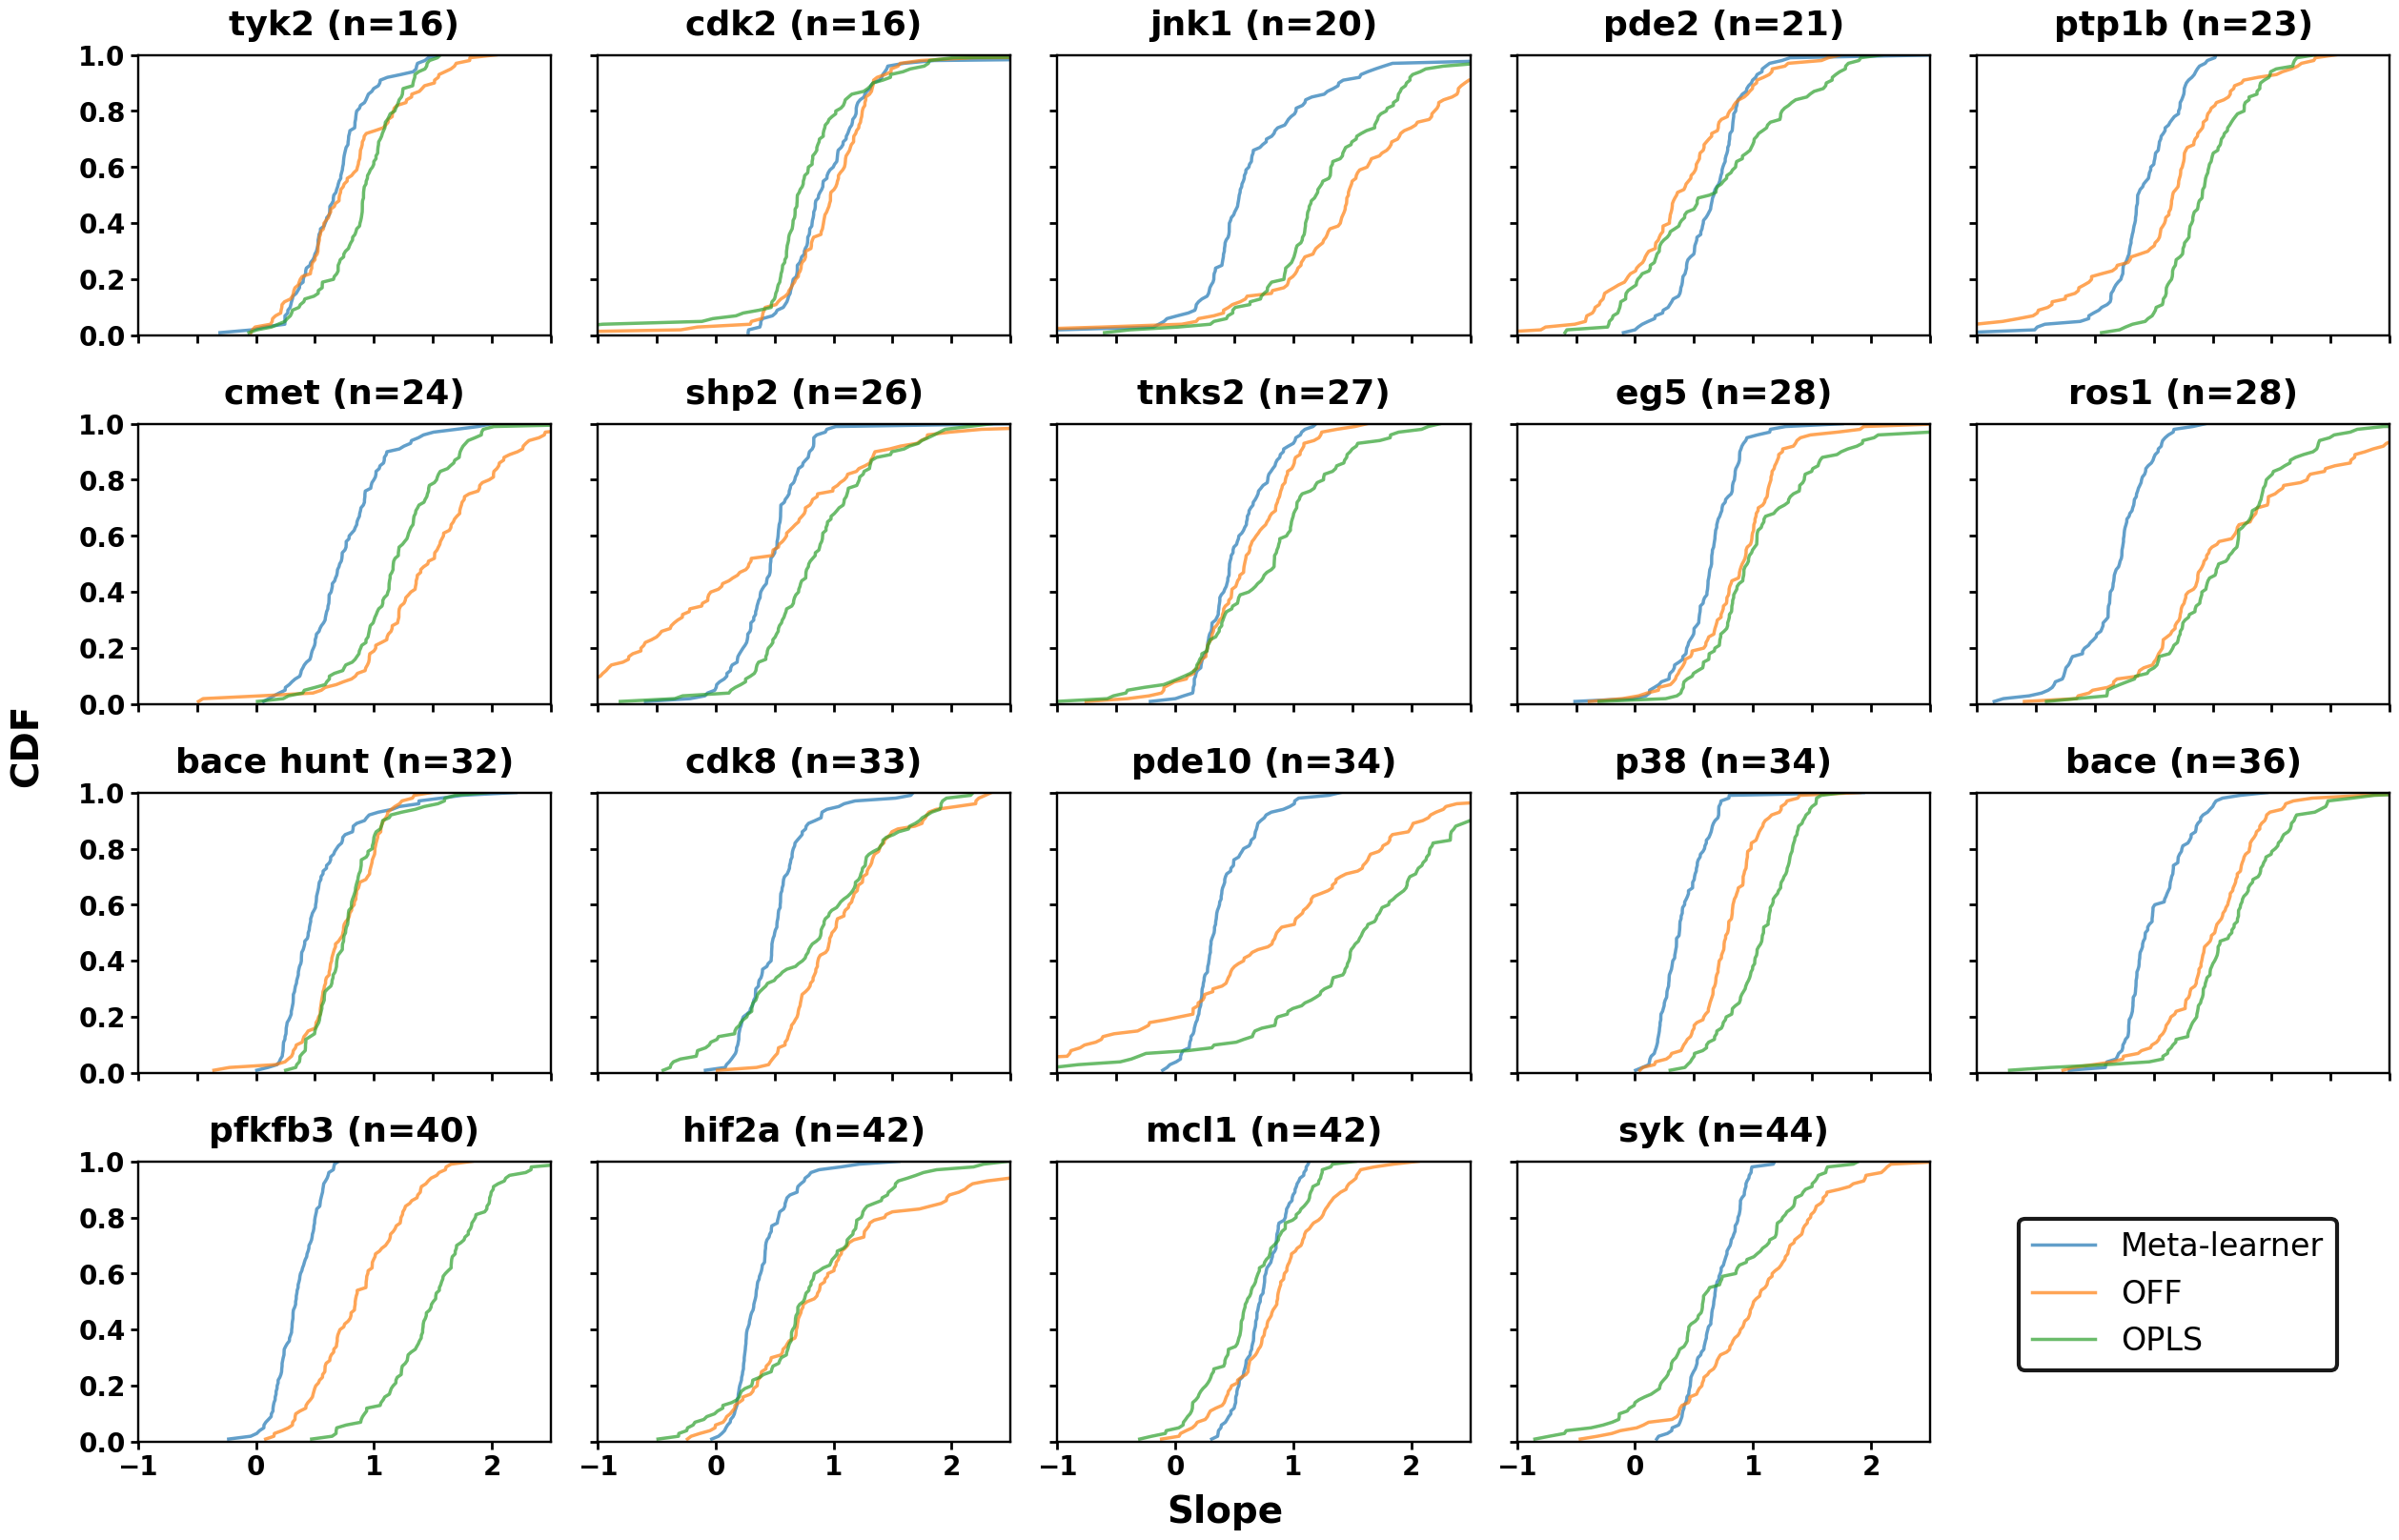

In [3]:
TITLE_FONT_SIZE = 26     # fontsize subplot titles
LABEL_FONT_SIZE = 28     # fontsize x/y axis labels
TICK_FONT_SIZE = 20      # fontsize x/y ticks
LEGEND_FONT_SIZE = 24    # fontsize legend
LEGEND_FRAME_ALPHA = 0.9 # transparency of legend box
LEGEND_EDGECOLOR = 'black' # legend border color
LEGEND_X = 0.9          # legend x position
LEGEND_Y = 0.14          # legend y position
alpha = 0.7      

# mapping for displayed names
NAME_MAP = {
    "p2": "bace_p2",
    "hunt": "bace hunt"
}

def plot_slope_cdfs(slopes_all, target_counts):
    """
    Plot grouped CDFs of slope by target, ordered ascending by count.
    Inputs:
      slopes_all (dict): method -> target -> split -> slope
      target_counts (dict): target -> total count
    """
    # sort targets ascending
    sorted_targets = [
        t for t in sorted(target_counts, key=lambda t: target_counts[t])
        if t not in TARGETS_TO_SKIP
    ]
    # enforce display order for methods
    methods = [m for m in DISPLAY_ORDER if m in slopes_all]

    cols = 5
    rows = math.ceil(len(sorted_targets) / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 4 * rows))
    axes = axes.flatten()

    for idx, target in enumerate(sorted_targets):
        ax = axes[idx]
        col = idx % cols
        row = idx // cols
        
        for method in methods:
            vals = list(slopes_all.get(method, {}).get(target, {}).values())
            if not vals:
                continue
            sorted_vals = np.sort(vals)
            cdf = np.arange(1, len(sorted_vals) + 1) / len(sorted_vals)
            ax.plot(sorted_vals, cdf, label=method, alpha=alpha, linewidth=2.5)

        ax.set_xlim(-1, 2.5)  # <- constant x-axis range
        ax.set_ylim(0, 1)     # Ensure y-axis from 0 to 1
        disp_name = NAME_MAP.get(target, target)
        ax.set_title(f"{disp_name} (n={target_counts[target]})", fontsize=TITLE_FONT_SIZE, fontweight='bold', pad=15)
        
        # Set all tick marks to same size
        ax.tick_params(axis='both', length=6, width=2)
        
        # Control tick label visibility
        if col == 0 and row == rows - 1:
            # Bottom-left corner: show both labels
            ax.tick_params(axis='both', labelsize=TICK_FONT_SIZE)
        elif col == 0:
            # Leftmost column: show y labels only
            ax.tick_params(axis='y', labelsize=TICK_FONT_SIZE)
            ax.tick_params(axis='x', labelbottom=False)
        elif row == rows - 1:
            # Bottom row: show x labels only
            ax.tick_params(axis='x', labelsize=TICK_FONT_SIZE)
            ax.tick_params(axis='y', labelleft=False)
        else:
            # Interior: hide all labels
            ax.tick_params(axis='both', labelbottom=False, labelleft=False)
        
        # Position bottom spine at y=0
        ax.spines['bottom'].set_position(('data', 0))
        
        # Make tick labels bold (after spine positioning)
        for label in ax.get_xticklabels() + ax.get_yticklabels():
            label.set_weight('bold')
        
        # Increase linewidth of subplot borders
        for spine in ax.spines.values():
            spine.set_linewidth(1.73)

    # Get legend handles and labels from first subplot
    handles, labels = axes[0].get_legend_handles_labels()
    
    # Create figure-level legend in bottom-right subplot position
    legend = fig.legend(handles, labels, fontsize=LEGEND_FONT_SIZE, framealpha=LEGEND_FRAME_ALPHA, 
               edgecolor=LEGEND_EDGECOLOR, fancybox=True, loc='center', bbox_to_anchor=(LEGEND_X, LEGEND_Y))
    legend.get_frame().set_linewidth(3)

    # remove unused axes
    for j in range(len(sorted_targets), len(axes)):
        fig.delaxes(axes[j])

    # Add single centered x and y labels for the entire figure
    fig.text(0.5, -0.01, 'Slope', ha='center', fontsize=LABEL_FONT_SIZE, fontweight='bold')
    fig.text(-0.01, 0.5, 'CDF', va='center', rotation='vertical', fontsize=LABEL_FONT_SIZE, fontweight='bold')

    plt.tight_layout(pad=2)
    plt.savefig("CDF.png", dpi=300, bbox_inches='tight', pad_inches=0.3)
    plt.show()

target_counts = load_target_counts(TARGET_COUNT_FILE)
plot_slope_cdfs(slopes, target_counts)